In [52]:
%matplotlib inline

import json
import re
import sys
import warnings
import zipfile

from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

In [53]:
pd.set_option("display.max_columns", 160)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

sns.set_theme(
    context="notebook",
    style="whitegrid",
    palette="mako",
)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10

In [54]:
root = Path.cwd()

for path in [Path.cwd(), *Path.cwd().parents]:
    if (path / "data").exists() and (path / "requirements.txt").exists():
        root = path
        break

if root.name != "music-analytics":
    fallback = Path.home() / "Documents" / "Coding" / "music-analytics"

    if fallback.exists():
        root = fallback

sys.path.insert(0, str(root))

In [55]:
data_root = root / "data"
raw_root = data_root / "raw"
raw_csv = raw_root / "csv"
raw_json = raw_root / "json_zips"

interim_root = data_root / "interim"
interim_csv = interim_root / "csv"
interim_json = interim_root / "json"

processed_root = data_root / "processed"
parquet_root = processed_root / "parquet"

metadata_root = data_root / "metadata"

reports_root = root / "reports"
figures_root = reports_root / "figures" / "data_check"
tables_root = reports_root / "tables" / "data_check"

figures_root.mkdir(parents=True, exist_ok=True)
tables_root.mkdir(parents=True, exist_ok=True)
metadata_root.mkdir(parents=True, exist_ok=True)

print("Project Root:", root)
print("Data Directory Exists:", data_root.exists())
print("Raw CSV Directory Exists:", raw_csv.exists())
print("Raw JSON Zip Directory Exists:", raw_json.exists())
print("Interim CSV Directory Exists:", interim_csv.exists())
print("Interim JSON Directory Exists:", interim_json.exists())
print("Processed Parquet Directory Exists:", parquet_root.exists())
print("Metadata Directory Exists:", metadata_root.exists())
print("Figures Directory:", figures_root)
print("Tables Directory:", tables_root)

Project Root: /Users/Sumaitat/Documents/Coding/music-analytics
Data Directory Exists: True
Raw CSV Directory Exists: True
Raw JSON Zip Directory Exists: True
Interim CSV Directory Exists: True
Interim JSON Directory Exists: True
Processed Parquet Directory Exists: True
Metadata Directory Exists: True
Figures Directory: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/data_check
Tables Directory: /Users/Sumaitat/Documents/Coding/music-analytics/reports/tables/data_check


In [56]:
def clean_name(value: str) -> str:
    value = str(value).strip().lower()
    value = re.sub(r"[^a-z0-9]+", "_", value)
    value = re.sub(r"_+", "_", value)
    return value.strip("_")

In [57]:
def table_name(path: Path) -> str:
    name = path.name
    name = name.replace(".json.zip", "")
    name = name.replace(".parquet", "")
    name = name.replace(".csv", "")
    name = name.replace(".json", "")
    return clean_name(name)

In [58]:
def kind(path: Path) -> str:
    if path.name.endswith(".json.zip"):
        return "json_zip"

    if path.name.endswith(".parquet"):
        return "parquet"

    if path.name.endswith(".csv"):
        return "csv"

    if path.name.endswith(".json"):
        return "json"

    return path.suffix.replace(".", "")


In [59]:
def layer(path: Path) -> str:
    path_text = path.as_posix()

    if "/data/raw/" in path_text:
        return "raw"

    if "/data/interim/" in path_text:
        return "interim"

    if "/data/processed/" in path_text:
        return "processed"

    if "/data/metadata/" in path_text:
        return "metadata"

    return "other"

In [60]:
def key(path: Path) -> str:
    return f"{layer(path)}__{kind(path)}__{table_name(path)}"

In [61]:
def save_table(dataframe: pd.DataFrame, name: str) -> Path:
    output = tables_root / name
    dataframe.to_csv(output, index=False)
    return output

In [62]:
def save_figure(name: str) -> Path:
    output = figures_root / name
    plt.savefig(output, dpi=200, bbox_inches="tight")
    return output

In [63]:
def memory(dataframe: pd.DataFrame) -> float:
    return round(dataframe.memory_usage(deep=True).sum() / 1_000_000, 3)

In [64]:
def hashable(value: Any) -> Any:
    if isinstance(value, (list, dict)):
        return json.dumps(value, ensure_ascii=False, sort_keys=True)

    return value

In [65]:
def duplicates(dataframe: pd.DataFrame) -> int:
    if dataframe.empty:
        return 0

    work = dataframe.map(hashable)
    return int(work.duplicated().sum())

In [66]:
def uniques(series: pd.Series) -> int:
    return int(series.dropna().map(hashable).nunique())

In [67]:
def samples(series: pd.Series, size: int = 5) -> str:
    values = (
        series
        .dropna()
        .map(hashable)
        .astype(str)
        .replace("", np.nan)
        .dropna()
        .drop_duplicates()
        .head(size)
        .tolist()
    )

    return " | ".join(values)

In [68]:
def read_json_zip(path: Path) -> pd.DataFrame:
    with zipfile.ZipFile(path, "r") as zip_file:
        names = zip_file.namelist()

        if not names:
            return pd.DataFrame()

        with zip_file.open(names[0]) as file:
            data = json.load(file)

    if isinstance(data, list):
        return pd.json_normalize(data)

    if isinstance(data, dict):
        for value in data.values():
            if isinstance(value, list):
                return pd.json_normalize(value)

        return pd.json_normalize(data)

    return pd.DataFrame()

In [69]:
def read_table(path: Path) -> pd.DataFrame:
    if path.name.endswith(".parquet"):
        return pd.read_parquet(path)

    if path.name.endswith(".csv"):
        return pd.read_csv(path, low_memory=False)

    if path.name.endswith(".json.zip"):
        return read_json_zip(path)

    if path.name.endswith(".json"):
        return read_json_file(path)

    raise ValueError(f"Unsupported File Type: {path.name}")

In [70]:
def family(column: str) -> str:
    name = clean_name(column)
    tokens = name.split("_")

    identifiers = [
        "identifier",
        "reference",
        "isrc",
        "upc",
        "playlist_id",
        "container_id",
        "recommendation_id",
        "session_id",
        "event_id",
        "track_id",
        "item_id",
        "adam_id",
        "catalog_id",
    ]

    dates = [
        "date",
        "time",
        "timestamp",
        "created",
        "modified",
        "started",
        "ended",
        "played",
        "received",
        "added",
    ]

    durations = [
        "duration",
        "millisecond",
        "milliseconds",
        "second",
        "seconds",
        "minute",
        "minutes",
        "position",
    ]

    counts = [
        "count",
        "plays",
        "skips",
        "rank",
        "ranking",
        "total",
        "number",
    ]

    metadata = [
        "song",
        "track",
        "title",
        "artist",
        "album",
        "genre",
        "disc",
        "movement",
        "work",
        "composer",
        "rating",
        "explicit",
        "artwork",
        "bpm",
        "tempo",
    ]

    contexts = [
        "source",
        "feature",
        "container",
        "playlist",
        "device",
        "os",
        "platform",
        "country",
        "language",
        "offline",
        "quality",
        "codec",
        "format",
        "shuffle",
        "repeat",
    ]

    preferences = [
        "favorite",
        "like",
        "dislike",
        "preference",
        "loved",
        "banned",
    ]

    if any(term in name for term in preferences):
        return "preference"

    if "id" in tokens or any(term in name for term in identifiers):
        return "identifier"

    if any(term in name for term in dates):
        return "date_time"

    if any(term in name for term in durations):
        return "duration"

    if any(term in name for term in counts):
        return "count"

    if any(term in name for term in contexts):
        return "context"

    if any(term in name for term in metadata):
        return "music_metadata"

    return "other"

In [71]:
def lookup(dataframe: pd.DataFrame) -> dict[str, str]:
    return {clean_name(column): column for column in dataframe.columns}

In [72]:
def find_column(dataframe: pd.DataFrame, candidates: list[str]) -> str | None:
    columns = lookup(dataframe)

    for candidate in candidates:
        clean_candidate = clean_name(candidate)

        if clean_candidate in columns:
            return columns[clean_candidate]

    return None

In [73]:
def join_value(value: Any) -> str | None:
    if pd.isna(value):
        return None

    text = str(value).strip()

    if not text:
        return None

    if re.fullmatch(r"\d+\.0", text):
        text = text[:-2]

    return text.lower()

In [74]:
def parse_dates(series: pd.Series) -> pd.Series:
    parsed = pd.to_datetime(series, errors="coerce", utc=True)

    if parsed.notna().mean() == 0:
        cleaned = (
            series
            .astype(str)
            .str.replace(r"\[UTC\]$", "", regex=True)
            .replace("nan", np.nan)
        )

        parsed = pd.to_datetime(cleaned, errors="coerce", utc=True)

    return parsed

In [75]:
def date_summary(series: pd.Series) -> dict[str, Any]:
    non_null = int(series.notna().sum())

    if non_null == 0:
        return {
            "parse_rate": 0,
            "min_date": pd.NaT,
            "max_date": pd.NaT,
        }

    parsed = parse_dates(series)
    parse_rate = round(parsed.notna().sum() / non_null, 4)

    return {
        "parse_rate": parse_rate,
        "min_date": parsed.min(),
        "max_date": parsed.max(),
    }

In [76]:
patterns = [
    "data/raw/csv/*.csv",
    "data/raw/json_zips/*.json.zip",
    "data/interim/csv/*.csv",
    "data/interim/json/*.json",
    "data/processed/parquet/*.parquet",
    "data/metadata/*.csv",
]

paths = []

for pattern in patterns:
    paths.extend(root.glob(pattern))

paths = sorted(set(paths))

In [77]:
files = pd.DataFrame(
    {
        "table_key": key(path),
        "file_name": path.name,
        "table_name": table_name(path),
        "file_type": kind(path),
        "data_layer": layer(path),
        "relative_path": str(path.relative_to(root)),
        "size_mb": round(path.stat().st_size / 1_000_000, 3),
    }
    for path in paths
)

files = files.sort_values(
    ["data_layer", "file_type", "table_name"]
).reset_index(drop=True)

save_table(files, "file_manifest.csv")

print("Discovered Files:", len(files))
display(files)

Discovered Files: 56


,table_key,file_name,table_name,file_type,data_layer,relative_path,size_mb
0,interim__csv__identifier_information,identifier_information.csv,identifier_information,csv,interim,data/interim/csv/identifier_information.csv,0.465
1,interim__csv__library_activity,library_activity.csv,library_activity,csv,interim,data/interim/csv/library_activity.csv,8.157
2,interim__csv__library_albums,library_albums.csv,library_albums,csv,interim,data/interim/csv/library_albums.csv,0.477
3,interim__csv__library_artists,library_artists.csv,library_artists,csv,interim,data/interim/csv/library_artists.csv,0.251
4,interim__csv__library_import_playlists,library_import_playlists.csv,library_import_playlists,csv,interim,data/interim/csv/library_import_playlists.csv,0.023
5,interim__csv__library_import_sessions,library_import_sessions.csv,library_import_sessions,csv,interim,data/interim/csv/library_import_sessions.csv,0.000
6,interim__csv__library_import_tracks,library_import_tracks.csv,library_import_tracks,csv,interim,data/interim/csv/library_import_tracks.csv,4.884
7,interim__csv__library_playlists,library_playlists.csv,library_playlists,csv,interim,data/interim/csv/library_playlists.csv,0.203
8,interim__csv__library_tracks,library_tracks.csv,library_tracks,csv,interim,data/interim/csv/library_tracks.csv,4.505
9,interim__json__identifier_information,identifier_information.json,identifier_information,json,interim,data/interim/json/identifier_information.json,1.150


In [78]:
tables = {}
load_rows = []

for path in paths:
    table_key = key(path)

    try:
        dataframe = read_table(path)
        tables[table_key] = dataframe

        load_rows.append(
            {
                "table_key": table_key,
                "file_name": path.name,
                "table_name": table_name(path),
                "file_type": kind(path),
                "data_layer": layer(path),
                "relative_path": str(path.relative_to(root)),
                "load_status": "Loaded",
                "row_count": dataframe.shape[0],
                "column_count": dataframe.shape[1],
                "memory_mb": memory(dataframe),
                "duplicate_rows": duplicates(dataframe),
                "error_message": "",
            }
        )

    except Exception as error:
        load_rows.append(
            {
                "table_key": table_key,
                "file_name": path.name,
                "table_name": table_name(path),
                "file_type": kind(path),
                "data_layer": layer(path),
                "relative_path": str(path.relative_to(root)),
                "load_status": "Failed",
                "row_count": np.nan,
                "column_count": np.nan,
                "memory_mb": np.nan,
                "duplicate_rows": np.nan,
                "error_message": str(error),
            }
        )

In [79]:
inventory = pd.DataFrame(load_rows)

inventory = inventory.sort_values(
    ["load_status", "data_layer", "row_count"],
    ascending=[True, True, False],
).reset_index(drop=True)

loaded = (
    inventory
    .query("load_status == 'Loaded'")
    .copy()
    .sort_values("row_count", ascending=False)
    .reset_index(drop=True)
)

save_table(inventory, "table_inventory.csv")

print("Loaded Tables:", len(tables))
print("Failed Tables:", int((inventory["load_status"] == "Failed").sum()))
print("Total Loaded Rows:", int(loaded["row_count"].sum()))
print("Total Loaded Columns:", int(loaded["column_count"].sum()))
print("Largest Table:", loaded.iloc[0]["table_key"])
print("Widest Table:", loaded.sort_values("column_count", ascending=False).iloc[0]["table_key"])

display(loaded)

Loaded Tables: 56
Failed Tables: 0
Total Loaded Rows: 266428
Total Loaded Columns: 1022
Largest Table: processed__parquet__play_activity_events
Widest Table: raw__csv__music_play_activity


,table_key,file_name,table_name,file_type,data_layer,relative_path,load_status,row_count,column_count,memory_mb,duplicate_rows,error_message
0,processed__parquet__play_activity_events,play_activity_events.parquet,play_activity_events,parquet,processed,data/processed/parquet/play_activity_events.pa...,Loaded,22872,32,9.949,0,
1,raw__csv__music_play_activity,music_play_activity.csv,music_play_activity,csv,raw,data/raw/csv/music_play_activity.csv,Loaded,22872,144,47.793,0,
2,interim__csv__identifier_information,identifier_information.csv,identifier_information,csv,interim,data/interim/csv/identifier_information.csv,Loaded,15260,2,0.679,0,
3,interim__json__identifier_information,identifier_information.json,identifier_information,json,interim,data/interim/json/identifier_information.json,Loaded,15260,2,0.677,0,
4,raw__json_zip__identifier_information,identifier_information.json.zip,identifier_information,json_zip,raw,data/raw/json_zips/identifier_information.json...,Loaded,15260,2,0.677,0,
5,processed__parquet__identifier_information,identifier_information.parquet,identifier_information,parquet,processed,data/processed/parquet/identifier_information....,Loaded,15260,2,0.677,0,
6,raw__json_zip__library_tracks,library_tracks.json.zip,library_tracks,json_zip,raw,data/raw/json_zips/library_tracks.json.zip,Loaded,10738,50,8.718,0,
7,interim__json__library_tracks,library_tracks.json,library_tracks,json,interim,data/interim/json/library_tracks.json,Loaded,10738,50,8.718,0,
8,interim__csv__library_tracks,library_tracks.csv,library_tracks,csv,interim,data/interim/csv/library_tracks.csv,Loaded,10738,50,8.716,0,
9,processed__parquet__library_tracks_clean,library_tracks_clean.parquet,library_tracks_clean,parquet,processed,data/processed/parquet/library_tracks_clean.pa...,Loaded,10738,52,7.754,0,


In [80]:
versions = (
    loaded
    .assign(canonical_name=lambda dataframe: dataframe["file_name"].map(lambda value: table_name(Path(value))))
    [
        [
            "canonical_name",
            "table_key",
            "file_name",
            "table_name",
            "file_type",
            "data_layer",
            "relative_path",
            "row_count",
            "column_count",
            "memory_mb",
            "duplicate_rows",
        ]
    ]
    .sort_values(["canonical_name", "data_layer", "file_type"])
    .reset_index(drop=True)
)

In [81]:
version_summary = (
    versions
    .groupby("canonical_name", as_index=False)
    .agg(
        version_count=("table_key", "count"),
        data_layers=("data_layer", lambda values: " | ".join(sorted(set(values)))),
        file_types=("file_type", lambda values: " | ".join(sorted(set(values)))),
        row_counts=("row_count", lambda values: " | ".join(map(str, sorted(set(values))))),
        column_counts=("column_count", lambda values: " | ".join(map(str, sorted(set(values))))),
        tables=("table_key", lambda values: " | ".join(values)),
    )
    .sort_values(["version_count", "canonical_name"], ascending=[False, True])
    .reset_index(drop=True)
)

save_table(versions, "canonical_versions.csv")
save_table(version_summary, "canonical_summary.csv")

display(version_summary)

,canonical_name,version_count,data_layers,file_types,row_counts,column_counts,tables
0,identifier_information,4,interim | processed | raw,csv | json | json_zip | parquet,15260,2,interim__csv__identifier_information | interim...
1,library_activity,4,interim | processed | raw,csv | json | json_zip | parquet,3842,35,interim__csv__library_activity | interim__json...
2,library_albums,4,interim | processed | raw,csv | json | json_zip | parquet,5255,6,interim__csv__library_albums | interim__json__...
3,library_artists,4,interim | processed | raw,csv | json | json_zip | parquet,3109,6,interim__csv__library_artists | interim__json_...
4,library_import_playlists,4,interim | processed | raw,csv | json | json_zip | parquet,88,11,interim__csv__library_import_playlists | inter...
5,library_import_sessions,4,interim | processed | raw,csv | json | json_zip | parquet,1,14,interim__csv__library_import_sessions | interi...
6,library_import_tracks,4,interim | processed | raw,csv | json | json_zip | parquet,9547,22,interim__csv__library_import_tracks | interim_...
7,library_playlists,4,interim | processed | raw,csv | json | json_zip | parquet,144,15,interim__csv__library_playlists | interim__jso...
8,library_tracks,4,interim | processed | raw,csv | json | json_zip | parquet,10738,50,interim__csv__library_tracks | interim__json__...
9,container_details,1,raw,csv,162,10,raw__csv__container_details


In [82]:
def get_key(canonical: str, data_layer: str | None = None, file_type: str | None = None) -> str | None:
    matches = versions.query("canonical_name == @canonical").copy()

    if data_layer is not None:
        matches = matches.query("data_layer == @data_layer").copy()

    if file_type is not None:
        matches = matches.query("file_type == @file_type").copy()

    if matches.empty:
        return None

    layer_rank = {
        "processed": 1,
        "interim": 2,
        "raw": 3,
        "metadata": 4,
    }

    type_rank = {
        "parquet": 1,
        "csv": 2,
        "json": 3,
        "json_zip": 4,
    }

    matches["layer_rank"] = matches["data_layer"].map(layer_rank).fillna(99)
    matches["type_rank"] = matches["file_type"].map(type_rank).fillna(99)

    return (
        matches
        .sort_values(["layer_rank", "type_rank", "row_count"], ascending=[True, True, False])
        .iloc[0]["table_key"]
    )

In [83]:
contract_rows = [
    {
        "canonical_name": "play_activity_events",
        "preferred_key": get_key("play_activity_events", "processed", "parquet"),
        "project_role": "Primary Detailed Playback Event Table",
        "grain": "One playback activity record per event",
        "next_use": "EDA Core",
        "dashboard_use": "Playback friction, completion, source context, device context, and sessionization",
        "model_use": "Implicit feedback, completion quality, skip-adjusted affinity, recency, and context features",
        "reason": "This is the cleaned event-level behavioral table and should replace raw music_play_activity for most analysis.",
    },
    {
        "canonical_name": "listening_events",
        "preferred_key": get_key("listening_events", "processed", "parquet"),
        "project_role": "Primary Summary Listening Table",
        "grain": "Track-level listening summary record",
        "next_use": "EDA Core",
        "dashboard_use": "Listening volume, repeat behavior, time trends, track-level summaries, and skip summaries",
        "model_use": "Track affinity, repeat behavior, skip rate, and long-term preference features",
        "reason": "This is the clean summary layer derived from daily track listening history.",
    },
    {
        "canonical_name": "library_tracks_clean",
        "preferred_key": get_key("library_tracks_clean", "processed", "parquet"),
        "project_role": "Primary Track Metadata Dimension",
        "grain": "One library track record per resolved library track",
        "next_use": "EDA Core",
        "dashboard_use": "Track, artist, album, genre, release year, duration, library state, and metadata enrichment",
        "model_use": "Candidate universe, content features, identity resolution, and metadata similarity",
        "reason": "This is the most analysis-ready track metadata table.",
    },
    {
        "canonical_name": "favorites_clean",
        "preferred_key": get_key("favorites_clean", "processed", "parquet"),
        "project_role": "Explicit Preference Table",
        "grain": "One explicit preference record per item",
        "next_use": "EDA Core",
        "dashboard_use": "Preference alignment, favorites coverage, and library affinity",
        "model_use": "Explicit preference boost and negative preference penalty",
        "reason": "Explicit preference is sparse but high-value for recommender readiness.",
    },
    {
        "canonical_name": "identifier_information",
        "preferred_key": get_key("identifier_information", "processed", "parquet"),
        "project_role": "Identifier Lookup Table",
        "grain": "One identifier-to-title lookup record",
        "next_use": "EDA Support",
        "dashboard_use": "Fallback label resolution for opaque identifiers",
        "model_use": "Fallback identity resolution",
        "reason": "This table helps reconcile identifiers that do not join cleanly through the track metadata table.",
    },
    {
        "canonical_name": "library_import_tracks",
        "preferred_key": get_key("library_import_tracks", "processed", "parquet"),
        "project_role": "Imported Track Metadata Table",
        "grain": "One imported track record per imported source track",
        "next_use": "EDA Support",
        "dashboard_use": "Imported catalog coverage and secondary metadata enrichment",
        "model_use": "External identifiers, imported track candidates, and metadata matching if reliable",
        "reason": "This table may improve identity coverage but should not override library_tracks_clean without join validation.",
    },
    {
        "canonical_name": "library_playlists",
        "preferred_key": get_key("library_playlists", "processed", "parquet"),
        "project_role": "Playlist Metadata Table",
        "grain": "One library playlist or container record",
        "next_use": "EDA Support",
        "dashboard_use": "Playlist structure, playlist size, playlist recency, and curation context",
        "model_use": "Playlist membership and container-based affinity if joins are reliable",
        "reason": "This supports playlist and container analysis but should not be treated as listening behavior.",
    },
    {
        "canonical_name": "library_activity",
        "preferred_key": get_key("library_activity", "processed", "parquet"),
        "project_role": "Library Curation Activity Table",
        "grain": "One library or playlist activity transaction",
        "next_use": "EDA Support",
        "dashboard_use": "Library curation, playlist edits, additions, and modification timelines",
        "model_use": "Recency and curation signals if transaction types are reliable",
        "reason": "This table is structurally sparse and should be analyzed by transaction type in EDA.",
    },
    {
        "canonical_name": "recent_impressions",
        "preferred_key": get_key("recent_impressions", "raw", "csv"),
        "project_role": "Recommendation Impression Sample",
        "grain": "One recent impression record",
        "next_use": "EDA Support",
        "dashboard_use": "Recommendation-adjacent exposure sample and validation only",
        "model_use": "Weak exposure signal only",
        "reason": "This table is small and duplicated, so it should not be used as a complete recommendation evaluation log.",
    },
    {
        "canonical_name": "recently_played_tracks",
        "preferred_key": get_key("recently_played_tracks", "raw", "csv"),
        "project_role": "Recent Track Snapshot",
        "grain": "One recent track summary record",
        "next_use": "EDA Support",
        "dashboard_use": "Recent behavior validation",
        "model_use": "Short-term recency checks",
        "reason": "This table is a recent snapshot, not the main behavioral history.",
    },
    {
        "canonical_name": "recently_played_containers",
        "preferred_key": get_key("recently_played_containers", "raw", "csv"),
        "project_role": "Recent Container Snapshot",
        "grain": "One recent container summary record",
        "next_use": "EDA Support",
        "dashboard_use": "Recent source and container validation",
        "model_use": "Recent container context if identifiers resolve",
        "reason": "This table is useful for recent context validation, not complete history.",
    },
    {
        "canonical_name": "container_details",
        "preferred_key": get_key("container_details", "raw", "csv"),
        "project_role": "Container Context Table",
        "grain": "One container detail record",
        "next_use": "EDA Support",
        "dashboard_use": "Container-level listening summaries and source context",
        "model_use": "Container affinity if joins resolve",
        "reason": "This may enrich playlist and source analysis but should be joined only after identifier validation.",
    },
    {
        "canonical_name": "container_origin",
        "preferred_key": get_key("container_origin", "raw", "csv"),
        "project_role": "Container Origin Table",
        "grain": "One container origin summary record",
        "next_use": "EDA Support",
        "dashboard_use": "Container origin and source attribution",
        "model_use": "Context features if joins resolve",
        "reason": "This table supports source attribution but is not a behavioral source of truth.",
    },
    {
        "canonical_name": "top_content",
        "preferred_key": get_key("top_content", "raw", "csv"),
        "project_role": "Validation Summary Table",
        "grain": "One exported top-content summary record",
        "next_use": "Validation Only",
        "dashboard_use": "Aggregate validation only",
        "model_use": "Do not use directly",
        "reason": "This is useful for checking computed metrics but should not drive the dashboard.",
    },
    {
        "canonical_name": "play_statistics",
        "preferred_key": get_key("play_statistics", "raw", "csv"),
        "project_role": "Validation Summary Table",
        "grain": "One exported play-statistic summary record",
        "next_use": "Validation Only",
        "dashboard_use": "Aggregate validation only",
        "model_use": "Do not use directly",
        "reason": "This is a validation table, not an event table.",
    },
    {
        "canonical_name": "feature_statistics",
        "preferred_key": get_key("feature_statistics", "raw", "csv"),
        "project_role": "Validation Summary Table",
        "grain": "One exported feature-statistic summary record",
        "next_use": "Validation Only",
        "dashboard_use": "Aggregate validation only",
        "model_use": "Do not use directly",
        "reason": "This is useful for validating source and feature totals.",
    },
    {
        "canonical_name": "music_play_activity",
        "preferred_key": get_key("music_play_activity", "raw", "csv"),
        "project_role": "Raw Detailed Playback Event Source",
        "grain": "One raw playback activity record per event",
        "next_use": "Raw Fallback Only",
        "dashboard_use": "Only when a needed field is missing from play_activity_events",
        "model_use": "Only when a needed field is missing from play_activity_events",
        "reason": "This table is wide and sparse. It should be preserved for lineage but not used as the default analytical table.",
    },
    {
        "canonical_name": "play_history_daily_tracks",
        "preferred_key": get_key("play_history_daily_tracks", "raw", "csv"),
        "project_role": "Raw Summary Listening Source",
        "grain": "One raw daily-track summary record",
        "next_use": "Raw Fallback Only",
        "dashboard_use": "Only when a needed field is missing from listening_events",
        "model_use": "Only when a needed field is missing from listening_events",
        "reason": "This is the raw source behind the cleaner listening_events table.",
    },
]

In [84]:
raw_contracts = pd.DataFrame(contract_rows)

missing_contracts = (
    raw_contracts
    .query("preferred_key.isna()", engine="python")
    .copy()
    .reset_index(drop=True)
)

save_table(missing_contracts, "missing_contracts.csv")

print("Missing Expected Contract Tables:", len(missing_contracts))
display(missing_contracts)

Missing Expected Contract Tables: 0


,canonical_name,preferred_key,project_role,grain,next_use,dashboard_use,model_use,reason


In [85]:
contracts = raw_contracts.dropna(subset=["preferred_key"]).reset_index(drop=True)

contracts = contracts.merge(
    loaded[
        [
            "table_key",
            "file_name",
            "data_layer",
            "file_type",
            "relative_path",
            "row_count",
            "column_count",
            "memory_mb",
            "duplicate_rows",
        ]
    ],
    left_on="preferred_key",
    right_on="table_key",
    how="left",
)

contracts = contracts.drop(columns=["table_key"])

eda_tables = (
    contracts
    .query("next_use in ['EDA Core', 'EDA Support', 'Validation Only']")
    .copy()
    .sort_values(["next_use", "row_count"], ascending=[True, False])
    .reset_index(drop=True)
)

chosen_keys = contracts["preferred_key"].dropna().drop_duplicates().tolist()
eda_keys = eda_tables["preferred_key"].dropna().drop_duplicates().tolist()

save_table(contracts, "table_contracts.csv")
save_table(eda_tables, "eda_input_tables.csv")

print("Selected Tables for Detailed Validation:", len(chosen_keys))
print("EDA Input Tables:", len(eda_keys))

display(contracts)
display(eda_tables)

Selected Tables for Detailed Validation: 18
EDA Input Tables: 16


,canonical_name,preferred_key,project_role,grain,next_use,dashboard_use,model_use,reason,file_name,data_layer,file_type,relative_path,row_count,column_count,memory_mb,duplicate_rows
0,play_activity_events,processed__parquet__play_activity_events,Primary Detailed Playback Event Table,One playback activity record per event,EDA Core,"Playback friction, completion, source context,...","Implicit feedback, completion quality, skip-ad...",This is the cleaned event-level behavioral tab...,play_activity_events.parquet,processed,parquet,data/processed/parquet/play_activity_events.pa...,22872,32,9.949,0
1,listening_events,processed__parquet__listening_events,Primary Summary Listening Table,Track-level listening summary record,EDA Core,"Listening volume, repeat behavior, time trends...","Track affinity, repeat behavior, skip rate, an...",This is the clean summary layer derived from d...,listening_events.parquet,processed,parquet,data/processed/parquet/listening_events.parquet,5042,21,1.552,0
2,library_tracks_clean,processed__parquet__library_tracks_clean,Primary Track Metadata Dimension,One library track record per resolved library ...,EDA Core,"Track, artist, album, genre, release year, dur...","Candidate universe, content features, identity...",This is the most analysis-ready track metadata...,library_tracks_clean.parquet,processed,parquet,data/processed/parquet/library_tracks_clean.pa...,10738,52,7.754,0
3,favorites_clean,processed__parquet__favorites_clean,Explicit Preference Table,One explicit preference record per item,EDA Core,"Preference alignment, favorites coverage, and ...",Explicit preference boost and negative prefere...,Explicit preference is sparse but high-value f...,favorites_clean.parquet,processed,parquet,data/processed/parquet/favorites_clean.parquet,156,6,0.016,0
4,identifier_information,processed__parquet__identifier_information,Identifier Lookup Table,One identifier-to-title lookup record,EDA Support,Fallback label resolution for opaque identifiers,Fallback identity resolution,This table helps reconcile identifiers that do...,identifier_information.parquet,processed,parquet,data/processed/parquet/identifier_information....,15260,2,0.677,0
5,library_import_tracks,processed__parquet__library_import_tracks,Imported Track Metadata Table,One imported track record per imported source ...,EDA Support,Imported catalog coverage and secondary metada...,"External identifiers, imported track candidate...",This table may improve identity coverage but s...,library_import_tracks.parquet,processed,parquet,data/processed/parquet/library_import_tracks.p...,9547,22,6.149,0
6,library_playlists,processed__parquet__library_playlists,Playlist Metadata Table,One library playlist or container record,EDA Support,"Playlist structure, playlist size, playlist re...",Playlist membership and container-based affini...,This supports playlist and container analysis ...,library_playlists.parquet,processed,parquet,data/processed/parquet/library_playlists.parquet,144,15,0.224,0
7,library_activity,processed__parquet__library_activity,Library Curation Activity Table,One library or playlist activity transaction,EDA Support,"Library curation, playlist edits, additions, a...",Recency and curation signals if transaction ty...,This table is structurally sparse and should b...,library_activity.parquet,processed,parquet,data/processed/parquet/library_activity.parquet,3842,35,9.024,0
8,recent_impressions,raw__csv__recent_impressions,Recommendation Impression Sample,One recent impression record,EDA Support,Recommendation-adjacent exposure sample and va...,Weak exposure signal only,"This table is small and duplicated, so it shou...",recent_impressions.csv,raw,csv,data/raw/csv/recent_impressions.csv,359,5,0.063,108
9,recently_played_tracks,raw__csv__recently_played_tracks,Recent Track Snapshot,One recent track summary record,EDA Support,Recent behavior validation,Short-term recency checks,"This table is a recent snapshot, not the main ...",recently_played_tracks.cs

,canonical_name,preferred_key,project_role,grain,next_use,dashboard_use,model_use,reason,file_name,data_layer,file_type,relative_path,row_count,column_count,memory_mb,duplicate_rows
0,play_activity_events,processed__parquet__play_activity_events,Primary Detailed Playback Event Table,One playback activity record per event,EDA Core,"Playback friction, completion, source context,...","Implicit feedback, completion quality, skip-ad...",This is the cleaned event-level behavioral tab...,play_activity_events.parquet,processed,parquet,data/processed/parquet/play_activity_events.pa...,22872,32,9.949,0
1,library_tracks_clean,processed__parquet__library_tracks_clean,Primary Track Metadata Dimension,One library track record per resolved library ...,EDA Core,"Track, artist, album, genre, release year, dur...","Candidate universe, content features, identity...",This is the most analysis-ready track metadata...,library_tracks_clean.parquet,processed,parquet,data/processed/parquet/library_tracks_clean.pa...,10738,52,7.754,0
2,listening_events,processed__parquet__listening_events,Primary Summary Listening Table,Track-level listening summary record,EDA Core,"Listening volume, repeat behavior, time trends...","Track affinity, repeat behavior, skip rate, an...",This is the clean summary layer derived from d...,listening_events.parquet,processed,parquet,data/processed/parquet/listening_events.parquet,5042,21,1.552,0
3,favorites_clean,processed__parquet__favorites_clean,Explicit Preference Table,One explicit preference record per item,EDA Core,"Preference alignment, favorites coverage, and ...",Explicit preference boost and negative prefere...,Explicit preference is sparse but high-value f...,favorites_clean.parquet,processed,parquet,data/processed/parquet/favorites_clean.parquet,156,6,0.016,0
4,identifier_information,processed__parquet__identifier_information,Identifier Lookup Table,One identifier-to-title lookup record,EDA Support,Fallback label resolution for opaque identifiers,Fallback identity resolution,This table helps reconcile identifiers that do...,identifier_information.parquet,processed,parquet,data/processed/parquet/identifier_information....,15260,2,0.677,0
5,library_import_tracks,processed__parquet__library_import_tracks,Imported Track Metadata Table,One imported track record per imported source ...,EDA Support,Imported catalog coverage and secondary metada...,"External identifiers, imported track candidate...",This table may improve identity coverage but s...,library_import_tracks.parquet,processed,parquet,data/processed/parquet/library_import_tracks.p...,9547,22,6.149,0
6,library_activity,processed__parquet__library_activity,Library Curation Activity Table,One library or playlist activity transaction,EDA Support,"Library curation, playlist edits, additions, a...",Recency and curation signals if transaction ty...,This table is structurally sparse and should b...,library_activity.parquet,processed,parquet,data/processed/parquet/library_activity.parquet,3842,35,9.024,0
7,recent_impressions,raw__csv__recent_impressions,Recommendation Impression Sample,One recent impression record,EDA Support,Recommendation-adjacent exposure sample and va...,Weak exposure signal only,"This table is small and duplicated, so it shou...",recent_impressions.csv,raw,csv,data/raw/csv/recent_impressions.csv,359,5,0.063,108
8,recently_played_tracks,raw__csv__recently_played_tracks,Recent Track Snapshot,One recent track summary record,EDA Support,Recent behavior validation,Short-term recency checks,"This table is a recent snapshot, not the main ...",recently_played_tracks.csv,raw,csv,data/raw/csv/recently_played_tracks.csv,200,22,0.087,0
9,container_details,raw__csv__container_details,Container Context Table,One container detail record,EDA Support,Container-level listening summaries and source...,Container affinity if joins resolve,This may enrich playlist and source analysis b...,container_details.csv,raw,csv,data/raw/csv/container_details.csv,162,10,0.026,0


In [86]:
all_rows = []

for table_key, dataframe in tables.items():
    record = loaded.loc[loaded["table_key"] == table_key].iloc[0]

    for column in dataframe.columns:
        series = dataframe[column]
        row_count = dataframe.shape[0]
        missing_count = int(series.isna().sum())
        non_null_count = int(series.notna().sum())

        all_rows.append(
            {
                "table_key": table_key,
                "file_name": record["file_name"],
                "table_name": record["table_name"],
                "data_layer": record["data_layer"],
                "file_type": record["file_type"],
                "column_name": column,
                "clean_column_name": clean_name(column),
                "column_family": family(column),
                "dtype": str(series.dtype),
                "row_count": row_count,
                "non_null_count": non_null_count,
                "missing_count": missing_count,
                "missing_rate": round(missing_count / row_count, 4) if row_count else 0,
                "unique_count": uniques(series),
                "sample_values": samples(series),
            }
        )

all_columns = pd.DataFrame(all_rows)

all_columns = all_columns.sort_values(
    ["table_key", "column_family", "missing_rate", "column_name"],
    ascending=[True, True, False, True],
).reset_index(drop=True)

save_table(all_columns, "column_inventory_all_tables.csv")

print("Profiled Columns Across All Tables:", len(all_columns))
display(all_columns.head(100))

Profiled Columns Across All Tables: 1022


,table_key,file_name,table_name,data_layer,file_type,column_name,clean_column_name,column_family,dtype,row_count,non_null_count,missing_count,missing_rate,unique_count,sample_values
0,interim__csv__identifier_information,identifier_information.csv,identifier_information,interim,csv,Identifier,identifier,identifier,str,15260,15260,0,0.000,15260,1852566185 | 1852566184 | 1792667027 | 1109658...
1,interim__csv__identifier_information,identifier_information.csv,identifier_information,interim,csv,Title,title,music_metadata,str,15260,15259,1,0.000,14162,House featuring John Cale | Wuthering Heights ...
2,interim__csv__library_activity,library_activity.csv,library_activity,interim,csv,Playlist.Description,playlist_description,context,str,3842,6,3836,0.998,5,fusion of classical music elements (orchestral...
3,interim__csv__library_activity,library_activity.csv,library_activity,interim,csv,Playlist.Playlist Previously Shared,playlist_playlist_previously_shared,context,object,3842,12,3830,0.997,1,True
4,interim__csv__library_activity,library_activity.csv,library_activity,interim,csv,User.Add Playlist Songs Setting,user_add_playlist_songs_setting,context,str,3842,20,3822,0.995,1,Playlist Only
5,interim__csv__library_activity,library_activity.csv,library_activity,interim,csv,Playlist.Playlist Is Shared,playlist_playlist_is_shared,context,object,3842,23,3819,0.994,2,False | True
6,interim__csv__library_activity,library_activity.csv,library_activity,interim,csv,Playlist.Container Type,playlist_container_type,context,str,3842,50,3792,0.987,3,Playlist | Favorites Playlist | Folder
7,interim__csv__library_activity,library_activity.csv,library_activity,interim,csv,Playlists,playlists,context,str,3842,88,3754,0.977,88,"[{""Added Date"": ""2025-10-17T23:53:30Z"", ""Conta..."
8,interim__csv__library_activity,library_activity.csv,library_activity,interim,csv,Playlist.Available On Apple Music Profile,playlist_available_on_apple_music_profile,context,object,3842,124,3718,0.968,2,False | True
9,interim__csv__library_activity,library_activity.csv,library_activity,interim,csv,Playlist.Title,playlist_title,context,str,3842,281,3561,0.927,211,Pop | RnB | p00p | Pop | Hyperpop


In [87]:
column_rows = []

for table_key in chosen_keys:
    dataframe = tables[table_key]
    record = loaded.loc[loaded["table_key"] == table_key].iloc[0]

    for column in dataframe.columns:
        series = dataframe[column]
        row_count = dataframe.shape[0]
        missing_count = int(series.isna().sum())
        non_null_count = int(series.notna().sum())

        column_rows.append(
            {
                "table_key": table_key,
                "file_name": record["file_name"],
                "table_name": record["table_name"],
                "data_layer": record["data_layer"],
                "file_type": record["file_type"],
                "column_name": column,
                "clean_column_name": clean_name(column),
                "column_family": family(column),
                "dtype": str(series.dtype),
                "row_count": row_count,
                "non_null_count": non_null_count,
                "missing_count": missing_count,
                "missing_rate": round(missing_count / row_count, 4) if row_count else 0,
                "unique_count": uniques(series),
                "sample_values": samples(series),
            }
        )

In [88]:
columns = pd.DataFrame(column_rows)

columns = columns.sort_values(
    ["table_key", "column_family", "missing_rate", "column_name"],
    ascending=[True, True, False, True],
).reset_index(drop=True)

save_table(columns, "column_inventory_selected_tables.csv")

print("Profiled Columns for Selected Tables:", len(columns))
display(columns)

Profiled Columns for Selected Tables: 417


,table_key,file_name,table_name,data_layer,file_type,column_name,clean_column_name,column_family,dtype,row_count,non_null_count,missing_count,missing_rate,unique_count,sample_values
0,processed__parquet__favorites_clean,favorites_clean.parquet,favorites_clean,processed,parquet,last_modified,last_modified,date_time,"datetime64[us, UTC]",156,8,148,0.949,7,2026-02-26 03:50:11.307000+00:00 | 2026-03-11 ...
1,processed__parquet__favorites_clean,favorites_clean.parquet,favorites_clean,processed,parquet,item_reference,item_reference,identifier,str,156,156,0,0.000,156,pl.38a8d4baa4f34cc79689bad25df20c85 | 17095549...
2,processed__parquet__favorites_clean,favorites_clean.parquet,favorites_clean,processed,parquet,item_description,item_description,other,str,156,155,1,0.006,155,Jung Kook - Standing Next to You | P1Harmony -...
3,processed__parquet__favorites_clean,favorites_clean.parquet,favorites_clean,processed,parquet,favorite_type,favorite_type,preference,str,156,156,0,0.000,2,Playlist | Song
4,processed__parquet__favorites_clean,favorites_clean.parquet,favorites_clean,processed,parquet,preference,preference,preference,str,156,156,0,0.000,3,NEUTRAL | LIKE | DISLIKE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
412,raw__csv__top_content,top_content.csv,top_content,raw,csv,First Played,first_played,date_time,int64,196,196,0,0.000,172,1760984179525 | 1760921847015 | 1760984682712 ...
413,raw__csv__top_content,top_content.csv,top_content,raw,csv,Last Played,last_played,date_time,int64,196,196,0,0.000,173,1767771152338 | 1768493950756 | 1768164416363 ...
414,raw__csv__top_content,top_content.csv,top_content,raw,csv,Last Received,last_received,date_time,int64,196,196,0,0.000,144,1767771855338 | 1768493950842 | 1768164134294 ...
415,raw__csv__top_content,top_content.csv,top_content,raw,csv,Play Duration Milliseconds,play_duration_milliseconds,duration,int64,196,196,0,0.000,191,20613974 | 15909360 | 11759958 | 11065156 | 10...


In [89]:
missing = (
    columns
    .groupby(["table_key", "table_name", "data_layer", "file_type"], as_index=False)
    .agg(
        column_count=("column_name", "count"),
        average_missing_rate=("missing_rate", "mean"),
        max_missing_rate=("missing_rate", "max"),
        fully_missing_columns=("missing_rate", lambda values: int((values == 1).sum())),
        mostly_missing_columns=("missing_rate", lambda values: int((values >= 0.75).sum())),
    )
)

missing["average_missing_rate"] = missing["average_missing_rate"].round(4)
missing["max_missing_rate"] = missing["max_missing_rate"].round(4)

missing = missing.sort_values(
    ["average_missing_rate", "mostly_missing_columns"],
    ascending=[False, False],
).reset_index(drop=True)

save_table(missing, "table_missingness_selected_tables.csv")

display(missing)

,table_key,table_name,data_layer,file_type,column_count,average_missing_rate,max_missing_rate,fully_missing_columns,mostly_missing_columns
0,processed__parquet__library_activity,library_activity,processed,parquet,35,0.767,1.000,0,25
1,raw__csv__music_play_activity,music_play_activity,raw,csv,144,0.546,1.000,32,64
2,processed__parquet__library_playlists,library_playlists,processed,parquet,15,0.412,0.993,0,6
3,processed__parquet__library_tracks_clean,library_tracks_clean,processed,parquet,52,0.366,1.000,1,19
4,raw__csv__recently_played_containers,recently_played_containers,raw,csv,11,0.226,1.000,2,2
5,processed__parquet__play_activity_events,play_activity_events,processed,parquet,32,0.208,0.711,0,0
6,raw__csv__recent_impressions,recent_impressions,raw,csv,5,0.164,0.549,0,0
7,processed__parquet__favorites_clean,favorites_clean,processed,parquet,6,0.159,0.949,0,1
8,raw__csv__container_details,container_details,raw,csv,10,0.138,1.000,1,1
9,raw__csv__container_origin,container_origin,raw,csv,8,0.129,1.000,1,1


In [90]:
families = (
    columns
    .groupby(["table_key", "column_family"], as_index=False)
    .agg(column_count=("column_name", "count"))
    .pivot(index="table_key", columns="column_family", values="column_count")
    .fillna(0)
    .astype(int)
    .reset_index()
)

save_table(families, "column_family_summary_selected_tables.csv")

display(families)

column_family,table_key,context,count,date_time,duration,identifier,music_metadata,other,preference
0,processed__parquet__favorites_clean,0,0,1,0,1,0,1,3
1,processed__parquet__identifier_information,0,0,0,0,1,1,0,0
2,processed__parquet__library_activity,9,1,7,0,10,2,4,2
3,processed__parquet__library_import_tracks,0,0,0,2,6,9,5,0
4,processed__parquet__library_playlists,3,1,4,0,4,1,2,0
5,processed__parquet__library_tracks_clean,2,8,6,4,3,15,10,4
6,processed__parquet__listening_events,1,3,1,2,2,3,9,0
7,processed__parquet__play_activity_events,13,0,3,6,1,2,7,0
8,raw__csv__container_details,2,1,2,1,0,3,1,0
9,raw__csv__container_origin,0,1,2,1,0,3,1,0


In [91]:
date_rows = []

date_columns = (
    columns
    .query("column_family == 'date_time'")
    .copy()
    .sort_values(["table_key", "column_name"])
)

for _, row in date_columns.iterrows():
    table_key = row["table_key"]
    column = row["column_name"]
    dataframe = tables[table_key]
    parsed = date_summary(dataframe[column])

    date_rows.append(
        {
            "table_key": table_key,
            "table_name": row["table_name"],
            "column_name": column,
            "dtype": row["dtype"],
            "non_null_count": row["non_null_count"],
            "unique_count": row["unique_count"],
            "parse_rate": parsed["parse_rate"],
            "min_date": parsed["min_date"],
            "max_date": parsed["max_date"],
            "sample_values": row["sample_values"],
        }
    )

dates = pd.DataFrame(date_rows)

if not dates.empty:
    dates = dates.sort_values(
        ["parse_rate", "table_key", "column_name"],
        ascending=[False, True, True],
    ).reset_index(drop=True)

save_table(dates, "date_audit_selected_tables.csv")

display(dates)

,table_key,table_name,column_name,dtype,non_null_count,unique_count,parse_rate,min_date,max_date,sample_values
0,processed__parquet__favorites_clean,favorites_clean,last_modified,"datetime64[us, UTC]",8,7,1.000,2026-01-29 06:13:04.664000+00:00,2026-03-11 04:01:07.496000+00:00,2026-02-26 03:50:11.307000+00:00 | 2026-03-11 ...
1,processed__parquet__library_activity,library_activity,Playlist.Added Date,str,49,49,1.000,2025-10-17 23:52:56+00:00,2026-03-02 23:43:45+00:00,2025-10-17T23:52:56Z | 2025-10-18T15:20:27Z | ...
2,processed__parquet__library_activity,library_activity,Playlist.Last Played Date,str,2,2,1.000,2026-03-11 00:39:43+00:00,2026-03-11 01:07:41+00:00,2026-03-11T00:39:43Z | 2026-03-11T01:07:41Z
3,processed__parquet__library_activity,library_activity,Playlist.Name or Description Modified Date,str,281,280,1.000,2025-10-17 23:52:58+00:00,2026-03-12 04:07:36+00:00,2025-10-17T23:52:58Z | 2025-10-18T13:35:40Z | ...
4,processed__parquet__library_activity,library_activity,Playlist.Playlist Items Modified Date,str,2116,2067,1.000,2025-10-17 23:52:58+00:00,2026-03-12 04:08:46+00:00,2025-10-17T23:52:58Z | 2025-10-18T01:34:32Z | ...
5,processed__parquet__library_activity,library_activity,Subscription Start Date,str,1,1,1.000,2025-10-17 23:50:10+00:00,2025-10-17 23:50:10+00:00,2025-10-17T23:50:10Z
6,processed__parquet__library_activity,library_activity,Transaction Date,str,3842,2834,1.000,2025-10-17 23:50:11+00:00,2026-03-12 04:08:46+00:00,2025-10-17T23:50:11Z | 2025-10-17T23:52:36Z | ...
7,processed__parquet__library_activity,library_activity,User.Subscription Start Date,str,20,1,1.000,2025-10-17 23:50:10+00:00,2025-10-17 23:50:10+00:00,2025-10-17T23:50:10Z
8,processed__parquet__library_playlists,library_playlists,Added Date,str,144,77,1.000,2025-10-17 23:52:56+00:00,2026-03-02 23:43:45+00:00,2025-10-21T04:00:09Z | 2025-10-17T23:52:56Z | ...
9,processed__parquet__library_playlists,library_playlists,Last Played Date,str,1,1,1.000,2026-03-11 01:07:41+00:00,2026-03-11 01:07:41+00:00,2026-03-11T01:07:41Z


In [92]:
numeric_rows = []
numeric_columns = (
    columns
    .query("column_family in ['duration', 'count']")
    .copy()
    .sort_values(["table_key", "column_name"])
)

for _, row in numeric_columns.iterrows():
    table_key = row["table_key"]
    column = row["column_name"]

    values = pd.to_numeric(tables[table_key][column], errors="coerce")

    if values.notna().sum() == 0:
        continue

    numeric_rows.append(
        {
            "table_key": table_key,
            "table_name": row["table_name"],
            "column_name": column,
            "column_family": row["column_family"],
            "non_null_numeric_count": int(values.notna().sum()),
            "minimum": values.min(),
            "p01": values.quantile(0.01),
            "p25": values.quantile(0.25),
            "median": values.median(),
            "mean": values.mean(),
            "p75": values.quantile(0.75),
            "p99": values.quantile(0.99),
            "maximum": values.max(),
            "zero_count": int((values == 0).sum()),
            "negative_count": int((values < 0).sum()),
        }
    )

numeric = pd.DataFrame(numeric_rows)

save_table(numeric, "numeric_audit_selected_tables.csv")

display(numeric)

,table_key,table_name,column_name,column_family,non_null_numeric_count,minimum,p01,p25,median,mean,p75,p99,maximum,zero_count,negative_count
0,processed__parquet__library_import_tracks,library_import_tracks,Track Duration,duration,9547,"4,626.000","62,832.300","154,741.000","197,877.000","209,612.544","243,785.500","570,364.220","1,975,124.000",0,0
1,processed__parquet__library_playlists,library_playlists,Play Count,count,1,7.000,7.000,7.000,7.000,7.000,7.000,7.000,7.000,0,0
2,processed__parquet__library_tracks_clean,library_tracks_clean,beats_per_minute,duration,26,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,26,0
3,processed__parquet__library_tracks_clean,library_tracks_clean,disc_count_of_album,count,10738,0.000,1.000,1.000,1.000,1.074,1.000,2.000,18.000,1,0
4,processed__parquet__library_tracks_clean,library_tracks_clean,disc_number_of_album,count,10738,0.000,1.000,1.000,1.000,1.028,1.000,2.000,13.000,1,0
5,processed__parquet__library_tracks_clean,library_tracks_clean,movement_count,count,50,0.000,0.000,0.000,0.000,3.620,4.000,24.000,24.000,26,0
6,processed__parquet__library_tracks_clean,library_tracks_clean,movement_number,count,50,0.000,0.000,0.000,0.000,1.540,2.000,16.650,24.000,26,0
7,processed__parquet__library_tracks_clean,library_tracks_clean,remember_playback_position,duration,26,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,26,0
8,processed__parquet__library_tracks_clean,library_tracks_clean,skip_count,count,10738,0.000,0.000,0.000,0.000,0.012,0.000,1.000,4.000,10618,0
9,processed__parquet__library_tracks_clean,library_tracks_clean,track_count_on_album,count,10737,0.000,1.000,7.000,12.000,12.828,16.000,55.000,131.000,1,0


In [93]:
millisecond_rows = []

for _, row in numeric_columns.iterrows():
    table_key = row["table_key"]
    column = row["column_name"]
    column_clean = clean_name(column)

    if "millisecond" not in column_clean and "millis" not in column_clean:
        continue

    values = pd.to_numeric(tables[table_key][column], errors="coerce")

    if values.notna().sum() == 0:
        continue

    minutes = values / 60_000

    millisecond_rows.append(
        {
            "table_key": table_key,
            "table_name": row["table_name"],
            "column_name": column,
            "non_null_count": int(values.notna().sum()),
            "total_hours": round(minutes.sum() / 60, 3),
            "mean_minutes": round(minutes.mean(), 3),
            "median_minutes": round(minutes.median(), 3),
            "p95_minutes": round(minutes.quantile(0.95), 3),
            "max_minutes": round(minutes.max(), 3),
        }
    )

durations = pd.DataFrame(millisecond_rows)

if not durations.empty:
    durations = durations.sort_values("total_hours", ascending=False).reset_index(drop=True)

save_table(durations, "millisecond_audit_selected_tables.csv")

display(durations)

,table_key,table_name,column_name,non_null_count,total_hours,mean_minutes,median_minutes,p95_minutes,max_minutes
0,raw__csv__music_play_activity,music_play_activity,Milliseconds Since Play,22872,"9,102.977",23.880,0.003,9.974,"18,685.217"
1,processed__parquet__play_activity_events,play_activity_events,media_duration_in_milliseconds,22870,"1,291.144",3.387,3.246,5.267,120.008
2,raw__csv__music_play_activity,music_play_activity,Media Duration In Milliseconds,22870,"1,291.144",3.387,3.246,5.267,120.008
3,raw__csv__music_play_activity,music_play_activity,End Position In Milliseconds,13820,233.546,1.014,0.157,3.595,101.750
4,processed__parquet__play_activity_events,play_activity_events,end_position_in_milliseconds,13820,233.546,1.014,0.157,3.595,101.750
5,processed__parquet__play_activity_events,play_activity_events,play_duration_milliseconds,13820,191.090,0.830,0.083,3.425,11.411
6,raw__csv__music_play_activity,music_play_activity,Play Duration Milliseconds,13820,191.090,0.830,0.083,3.425,11.411
7,raw__csv__play_history_daily_tracks,play_history_daily_tracks,Play Duration Milliseconds,5042,150.182,1.787,0.000,6.710,133.973
8,processed__parquet__listening_events,listening_events,play_duration_milliseconds,5042,150.182,1.787,0.000,6.710,133.973
9,raw__csv__top_content,top_content,Play Duration Milliseconds,196,91.229,27.927,4.426,95.872,"1,258.315"


In [94]:
def unique_values(dataframe: pd.DataFrame, join_columns: list[str]) -> pd.Series:
    if len(join_columns) == 1:
        values = dataframe[join_columns[0]].map(join_value)
        return values.dropna().drop_duplicates()

    values = dataframe[join_columns].copy()
    values = values.map(join_value).dropna()

    if values.empty:
        return pd.Series(dtype="object")

    combined = values.astype(str).agg(" || ".join, axis=1)
    return combined.dropna().drop_duplicates()

In [95]:
def test_join(
    left_key: str,
    right_key: str,
    left_candidates: list[str],
    right_candidates: list[str],
    join_name: str,
) -> dict[str, Any]:
    left = tables[left_key]
    right = tables[right_key]

    left_columns = []

    for candidate in left_candidates:
        column = find_column(left, [candidate])

        if column is not None:
            left_columns.append(column)

    right_columns = []

    for candidate in right_candidates:
        column = find_column(right, [candidate])

        if column is not None:
            right_columns.append(column)

    if len(left_columns) != len(left_candidates) or len(right_columns) != len(right_candidates):
        return {
            "join_name": join_name,
            "left_table": left_key,
            "right_table": right_key,
            "left_columns": " | ".join(left_candidates),
            "right_columns": " | ".join(right_candidates),
            "left_unique_values": np.nan,
            "right_unique_values": np.nan,
            "overlap_unique_values": np.nan,
            "left_overlap_rate": np.nan,
            "right_overlap_rate": np.nan,
            "status": "Skipped Missing Column",
        }

    left_values = unique_values(left, left_columns)
    right_values = unique_values(right, right_columns)

    if len(left_values) == 0 or len(right_values) == 0:
        return {
            "join_name": join_name,
            "left_table": left_key,
            "right_table": right_key,
            "left_columns": " | ".join(left_columns),
            "right_columns": " | ".join(right_columns),
            "left_unique_values": len(left_values),
            "right_unique_values": len(right_values),
            "overlap_unique_values": 0,
            "left_overlap_rate": 0,
            "right_overlap_rate": 0,
            "status": "No Joinable Values",
        }

    left_set = set(left_values)
    right_set = set(right_values)
    overlap_count = len(left_set.intersection(right_set))

    return {
        "join_name": join_name,
        "left_table": left_key,
        "right_table": right_key,
        "left_columns": " | ".join(left_columns),
        "right_columns": " | ".join(right_columns),
        "left_unique_values": len(left_set),
        "right_unique_values": len(right_set),
        "overlap_unique_values": overlap_count,
        "left_overlap_rate": round(overlap_count / len(left_set), 4),
        "right_overlap_rate": round(overlap_count / len(right_set), 4),
        "status": "Tested",
    }

In [96]:
play_activity_key = get_key("play_activity_events", "processed", "parquet")
listening_key = get_key("listening_events", "processed", "parquet")
library_key = get_key("library_tracks_clean", "processed", "parquet")
favorites_key = get_key("favorites_clean", "processed", "parquet")
identifier_key = get_key("identifier_information", "processed", "parquet")
imports_key = get_key("library_import_tracks", "processed", "parquet")
playlists_key = get_key("library_playlists", "processed", "parquet")
container_key = get_key("container_details", "raw", "csv")
origin_key = get_key("container_origin", "raw", "csv")

join_specs = []

In [97]:
if listening_key and library_key:
    join_specs.extend(
        [
            {
                "join_name": "listening_to_library_by_reference",
                "left_key": listening_key,
                "right_key": library_key,
                "left_candidates": ["track_reference"],
                "right_candidates": ["apple_music_track_identifier"],
            },
            {
                "join_name": "listening_to_library_by_identifier",
                "left_key": listening_key,
                "right_key": library_key,
                "left_candidates": ["track_identifier"],
                "right_candidates": ["track_identifier"],
            },
            {
                "join_name": "listening_to_library_by_title_artist",
                "left_key": listening_key,
                "right_key": library_key,
                "left_candidates": ["title_from_description", "artist_from_description"],
                "right_candidates": ["title", "artist"],
            },
        ]
    )

In [98]:
if play_activity_key and library_key:
    join_specs.extend(
        [
            {
                "join_name": "activity_to_library_by_song",
                "left_key": play_activity_key,
                "right_key": library_key,
                "left_candidates": ["song_name"],
                "right_candidates": ["title"],
            },
            {
                "join_name": "activity_to_library_by_song_artist",
                "left_key": play_activity_key,
                "right_key": library_key,
                "left_candidates": ["song_name", "artist_name"],
                "right_candidates": ["title", "artist"],
            },
        ]
    )

In [99]:
if favorites_key and library_key:
    join_specs.extend(
        [
            {
                "join_name": "favorites_to_library_by_catalog_id",
                "left_key": favorites_key,
                "right_key": library_key,
                "left_candidates": ["item_reference"],
                "right_candidates": ["apple_music_track_identifier"],
            },
            {
                "join_name": "favorites_to_library_by_track_id",
                "left_key": favorites_key,
                "right_key": library_key,
                "left_candidates": ["item_reference"],
                "right_candidates": ["track_identifier"],
            },
        ]
    )

In [100]:
if identifier_key and library_key:
    join_specs.extend(
        [
            {
                "join_name": "identifier_to_library_by_track_id",
                "left_key": identifier_key,
                "right_key": library_key,
                "left_candidates": ["identifier"],
                "right_candidates": ["track_identifier"],
            },
            {
                "join_name": "identifier_to_library_by_catalog_id",
                "left_key": identifier_key,
                "right_key": library_key,
                "left_candidates": ["identifier"],
                "right_candidates": ["apple_music_track_identifier"],
            },
        ]
    )

In [101]:
if imports_key and library_key:
    join_specs.extend(
        [
            {
                "join_name": "imports_to_library_by_imported_id",
                "left_key": imports_key,
                "right_key": library_key,
                "left_candidates": ["imported_library_track_id"],
                "right_candidates": ["track_identifier"],
            },
            {
                "join_name": "imports_to_library_by_matched_ids",
                "left_key": imports_key,
                "right_key": library_key,
                "left_candidates": ["matched_ids"],
                "right_candidates": ["apple_music_track_identifier"],
            },
            {
                "join_name": "imports_to_library_by_track_artist",
                "left_key": imports_key,
                "right_key": library_key,
                "left_candidates": ["track_name", "track_artist_name"],
                "right_candidates": ["title", "artist"],
            },
        ]
    )

In [102]:
if container_key and origin_key:
    join_specs.append(
        {
            "join_name": "container_to_origin_by_description",
            "left_key": container_key,
            "right_key": origin_key,
            "left_candidates": ["container_description"],
            "right_candidates": ["container_description"],
        }
    )

In [103]:
join_rows = []

for spec in join_specs:
    join_rows.append(
        test_join(
            left_key=spec["left_key"],
            right_key=spec["right_key"],
            left_candidates=spec["left_candidates"],
            right_candidates=spec["right_candidates"],
            join_name=spec["join_name"],
        )
    )

In [104]:
joins = pd.DataFrame(join_rows)

if not joins.empty:
    joins = joins.sort_values(
        ["status", "left_overlap_rate", "overlap_unique_values"],
        ascending=[True, False, False],
    ).reset_index(drop=True)

save_table(joins, "join_quality_report.csv")

display(joins)

,join_name,left_table,right_table,left_columns,right_columns,left_unique_values,right_unique_values,overlap_unique_values,left_overlap_rate,right_overlap_rate,status
0,activity_to_library_by_song_artist,processed__parquet__play_activity_events,processed__parquet__library_tracks_clean,song_name | artist_name,title | artist,NaN,NaN,NaN,NaN,NaN,Skipped Missing Column
1,container_to_origin_by_description,raw__csv__container_details,raw__csv__container_origin,container_description,container_description,NaN,NaN,NaN,NaN,NaN,Skipped Missing Column
2,imports_to_library_by_imported_id,processed__parquet__library_import_tracks,processed__parquet__library_tracks_clean,Imported Library Track ID,track_identifier,"9,190.000","10,738.000","9,189.000",1.000,0.856,Tested
3,favorites_to_library_by_catalog_id,processed__parquet__favorites_clean,processed__parquet__library_tracks_clean,item_reference,apple_music_track_identifier,156.000,"10,633.000",155.000,0.994,0.015,Tested
4,listening_to_library_by_reference,processed__parquet__listening_events,processed__parquet__library_tracks_clean,track_reference,apple_music_track_identifier,"2,643.000","10,633.000","2,079.000",0.787,0.196,Tested
5,activity_to_library_by_song,processed__parquet__play_activity_events,processed__parquet__library_tracks_clean,song_name,title,"3,057.000","9,638.000","2,245.000",0.734,0.233,Tested
6,imports_to_library_by_track_artist,processed__parquet__library_import_tracks,processed__parquet__library_tracks_clean,Track Name | Track Artist Name,title | artist,"9,190.000","10,227.000","6,510.000",0.708,0.637,Tested
7,listening_to_library_by_title_artist,processed__parquet__listening_events,processed__parquet__library_tracks_clean,title_from_description | artist_from_description,title | artist,"2,792.000","10,227.000","1,977.000",0.708,0.193,Tested
8,identifier_to_library_by_catalog_id,processed__parquet__identifier_information,processed__parquet__library_tracks_clean,Identifier,apple_music_track_identifier,"15,260.000","10,633.000","10,633.000",0.697,1.000,Tested
9,listening_to_library_by_identifier,processed__parquet__listening_events,processed__parquet__library_tracks_clean,track_identifier,track_identifier,"2,907.000","10,738.000",0.000,0.000,0.000,Tested


In [105]:
ready_rows = []

for _, row in contracts.iterrows():
    table_key = row["preferred_key"]
    table_columns = columns.query("table_key == @table_key").copy()

    if table_columns.empty:
        continue

    identifier_count = int((table_columns["column_family"] == "identifier").sum())
    date_count = int((table_columns["column_family"] == "date_time").sum())
    duration_count = int((table_columns["column_family"] == "duration").sum())
    count_count = int((table_columns["column_family"] == "count").sum())
    metadata_count = int((table_columns["column_family"] == "music_metadata").sum())
    context_count = int((table_columns["column_family"] == "context").sum())
    preference_count = int((table_columns["column_family"] == "preference").sum())

    average_missing = table_columns["missing_rate"].mean()
    row_count = int(row["row_count"])
    column_count = int(row["column_count"])

    score = (
        min(row_count / 10_000, 1) * 2.0
        + min(column_count / 40, 1) * 1.0
        + min(identifier_count / 3, 1) * 1.5
        + min(date_count / 2, 1) * 1.0
        + min(duration_count / 2, 1) * 1.0
        + min((metadata_count + context_count + preference_count) / 10, 1) * 1.5
        + (1 - average_missing) * 2.0
    )

    if row["next_use"] == "EDA Core":
        status = "Ready for EDA Core Validation"
    elif row["next_use"] == "EDA Support":
        status = "Ready for EDA Support Validation"
    elif row["next_use"] == "Validation Only":
        status = "Validation Only"
    else:
        status = "Raw Fallback Only"

    ready_rows.append(
        {
            "table_key": table_key,
            "canonical_name": row["canonical_name"],
            "project_role": row["project_role"],
            "next_use": row["next_use"],
            "readiness_status": status,
            "row_count": row_count,
            "column_count": column_count,
            "identifier_columns": identifier_count,
            "date_columns": date_count,
            "duration_columns": duration_count,
            "count_columns": count_count,
            "music_metadata_columns": metadata_count,
            "context_columns": context_count,
            "preference_columns": preference_count,
            "average_missing_rate": round(average_missing, 4),
            "readiness_score": round(score, 3),
        }
    )

In [106]:
readiness = pd.DataFrame(ready_rows)

readiness = readiness.sort_values(
    ["next_use", "readiness_score"],
    ascending=[True, False],
).reset_index(drop=True)

save_table(readiness, "table_readiness.csv")

display(readiness)

,table_key,canonical_name,project_role,next_use,readiness_status,row_count,column_count,identifier_columns,date_columns,duration_columns,count_columns,music_metadata_columns,context_columns,preference_columns,average_missing_rate,readiness_score
0,processed__parquet__library_tracks_clean,library_tracks_clean,Primary Track Metadata Dimension,EDA Core,Ready for EDA Core Validation,10738,52,3,6,4,8,15,2,4,0.366,9.268
1,processed__parquet__play_activity_events,play_activity_events,Primary Detailed Playback Event Table,EDA Core,Ready for EDA Core Validation,22872,32,1,3,6,0,2,13,0,0.208,8.384
2,processed__parquet__listening_events,listening_events,Primary Summary Listening Table,EDA Core,Ready for EDA Core Validation,5042,21,2,1,2,3,3,1,0,0.004,6.626
3,processed__parquet__favorites_clean,favorites_clean,Explicit Preference Table,EDA Core,Ready for EDA Core Validation,156,6,1,1,0,0,0,0,3,0.159,3.313
4,processed__parquet__library_import_tracks,library_import_tracks,Imported Track Metadata Table,EDA Support,Ready for EDA Support Validation,9547,22,6,0,2,0,9,0,0,0.000,8.309
5,raw__csv__recently_played_tracks,recently_played_tracks,Recent Track Snapshot,EDA Support,Ready for EDA Support Validation,200,22,2,5,5,3,1,3,0,0.019,6.153
6,processed__parquet__library_activity,library_activity,Library Curation Activity Table,EDA Support,Ready for EDA Support Validation,3842,35,10,7,0,1,2,9,2,0.767,6.109
7,processed__parquet__identifier_information,identifier_information,Identifier Lookup Table,EDA Support,Ready for EDA Support Validation,15260,2,1,0,0,0,1,0,0,0.000,4.700
8,processed__parquet__library_playlists,library_playlists,Playlist Metadata Table,EDA Support,Ready for EDA Support Validation,144,15,4,4,0,1,1,3,0,0.412,4.679
9,raw__csv__recently_played_containers,recently_played_containers,Recent Container Snapshot,EDA Support,Ready for EDA Support Validation,50,11,2,2,0,3,1,2,0,0.226,4.284


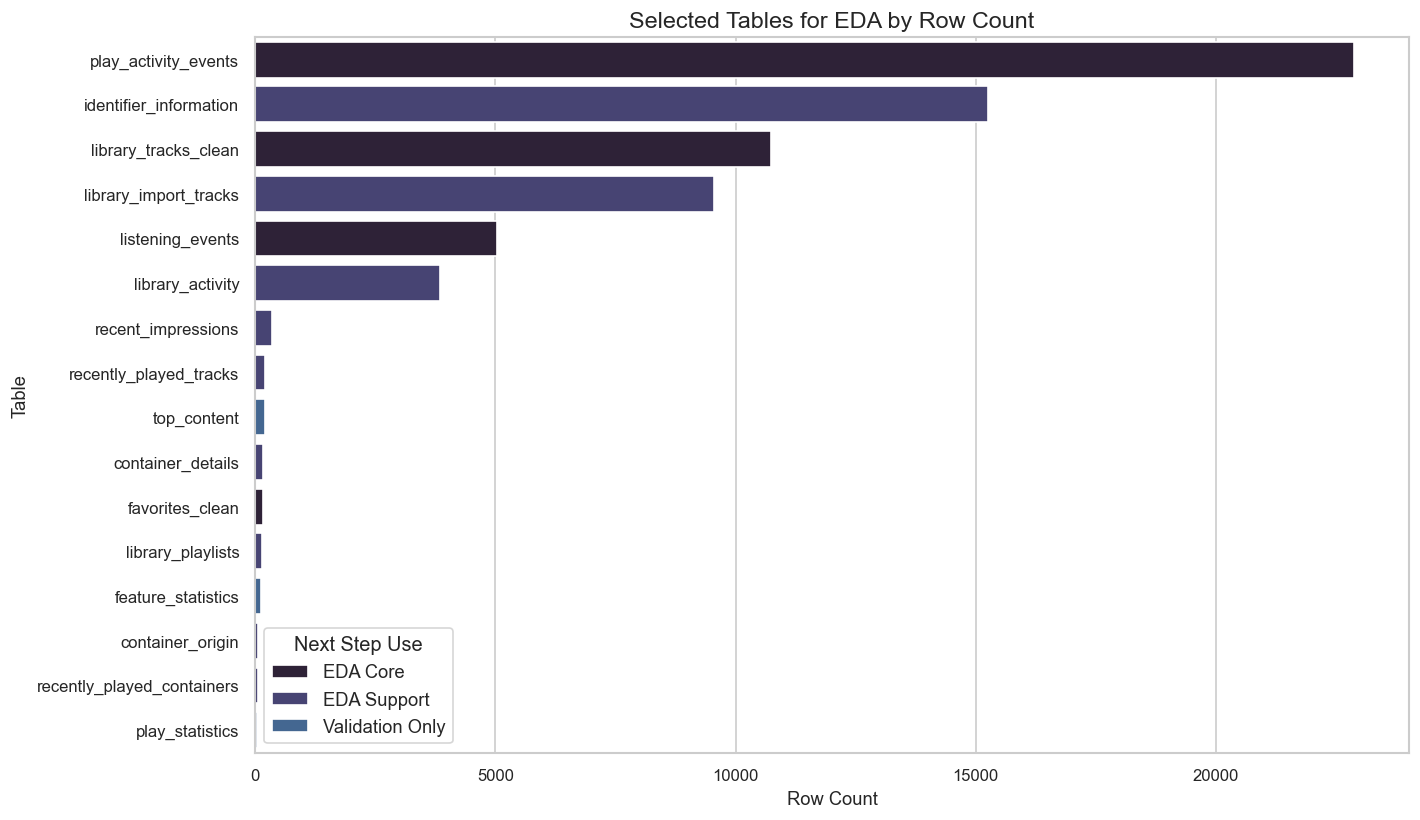

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/data_check/selected_tables_for_eda_by_row_count.png


In [107]:
plot_data = (
    contracts
    .query("next_use in ['EDA Core', 'EDA Support', 'Validation Only']")
    .copy()
    .sort_values("row_count", ascending=False)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=plot_data,
    x="row_count",
    y="canonical_name",
    hue="next_use",
    dodge=False,
)

plt.title("Selected Tables for EDA by Row Count")
plt.xlabel("Row Count")
plt.ylabel("Table")
plt.legend(title="Next Step Use")
plt.tight_layout()

figure_path = save_figure("selected_tables_for_eda_by_row_count.png")
plt.show()

print("Saved Figure:", figure_path)

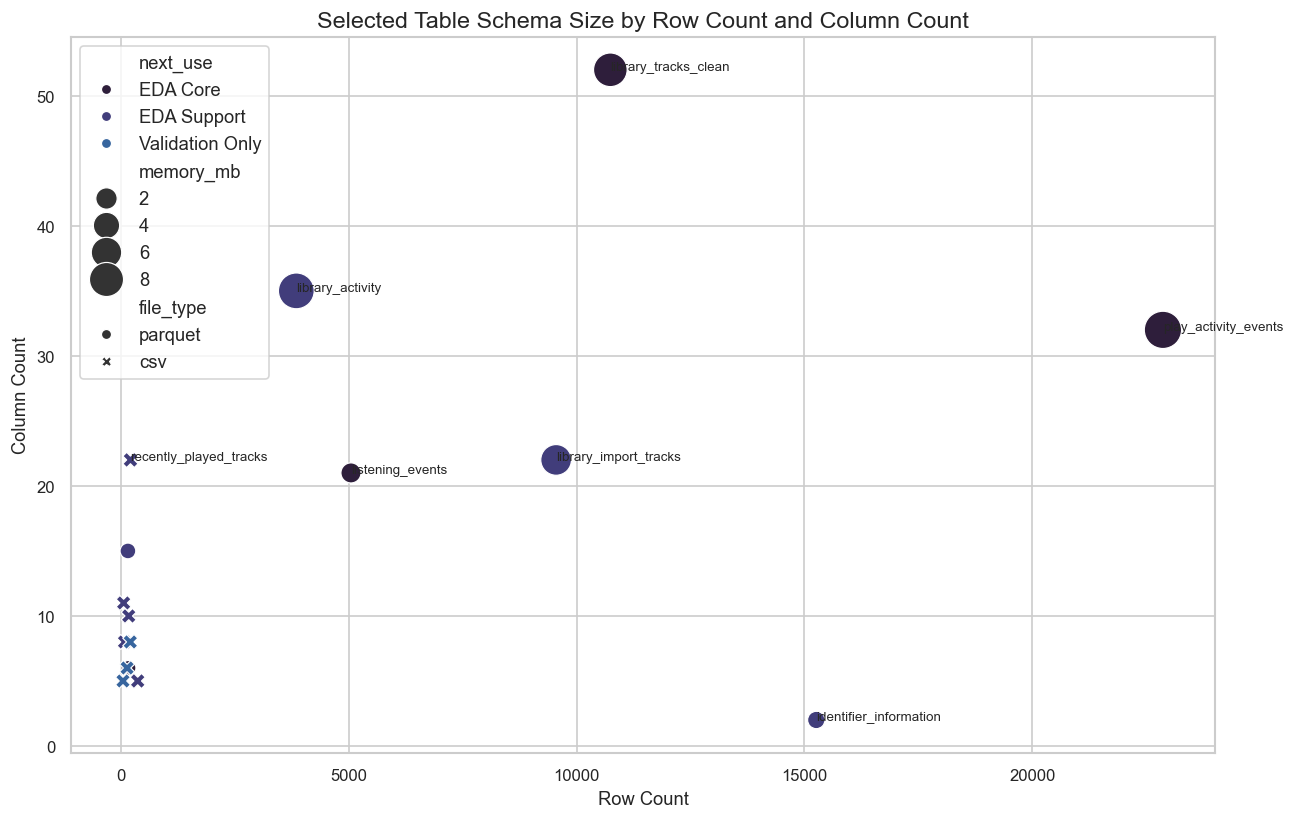

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/data_check/selected_schema_size_by_row_count_and_column_count.png


In [108]:
plot_data = (
    contracts
    .query("next_use in ['EDA Core', 'EDA Support', 'Validation Only']")
    .copy()
)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=plot_data,
    x="row_count",
    y="column_count",
    hue="next_use",
    style="file_type",
    size="memory_mb",
    sizes=(80, 500),
)

for _, row in plot_data.iterrows():
    if row["row_count"] >= 1_000 or row["column_count"] >= 20:
        plt.text(
            row["row_count"],
            row["column_count"],
            row["canonical_name"],
            fontsize=8,
        )

plt.title("Selected Table Schema Size by Row Count and Column Count")
plt.xlabel("Row Count")
plt.ylabel("Column Count")
plt.tight_layout()

figure_path = save_figure("selected_schema_size_by_row_count_and_column_count.png")
plt.show()

print("Saved Figure:", figure_path)

In [109]:
plot_data = missing.merge(
    contracts[["preferred_key", "canonical_name", "next_use"]],
    left_on="table_key",
    right_on="preferred_key",
    how="left",
)

plot_data = plot_data.sort_values("average_missing_rate", ascending=False)

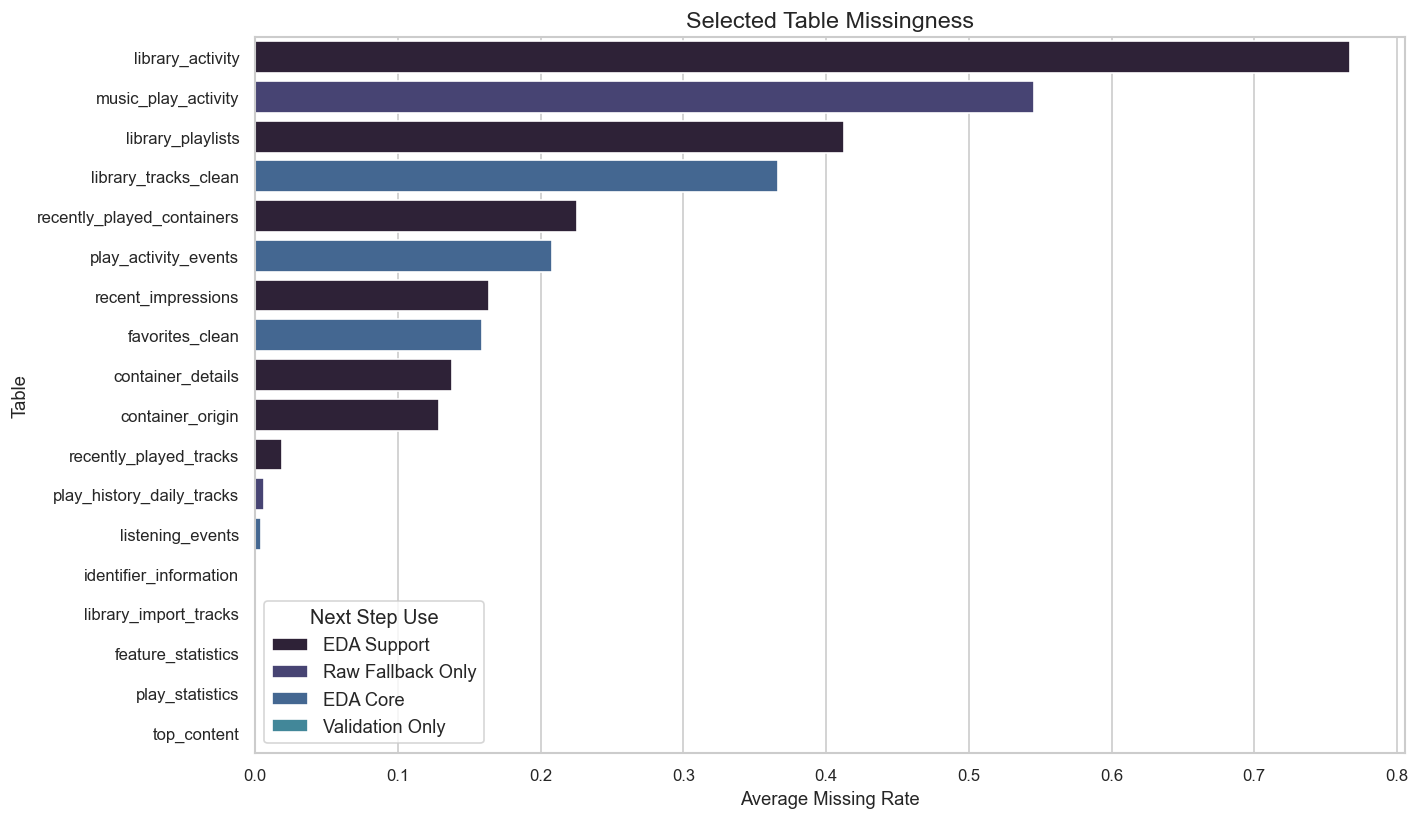

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/data_check/selected_table_missingness.png


In [110]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=plot_data,
    x="average_missing_rate",
    y="canonical_name",
    hue="next_use",
    dodge=False,
)

plt.title("Selected Table Missingness")
plt.xlabel("Average Missing Rate")
plt.ylabel("Table")
plt.legend(title="Next Step Use")
plt.tight_layout()

figure_path = save_figure("selected_table_missingness.png")
plt.show()

print("Saved Figure:", figure_path)

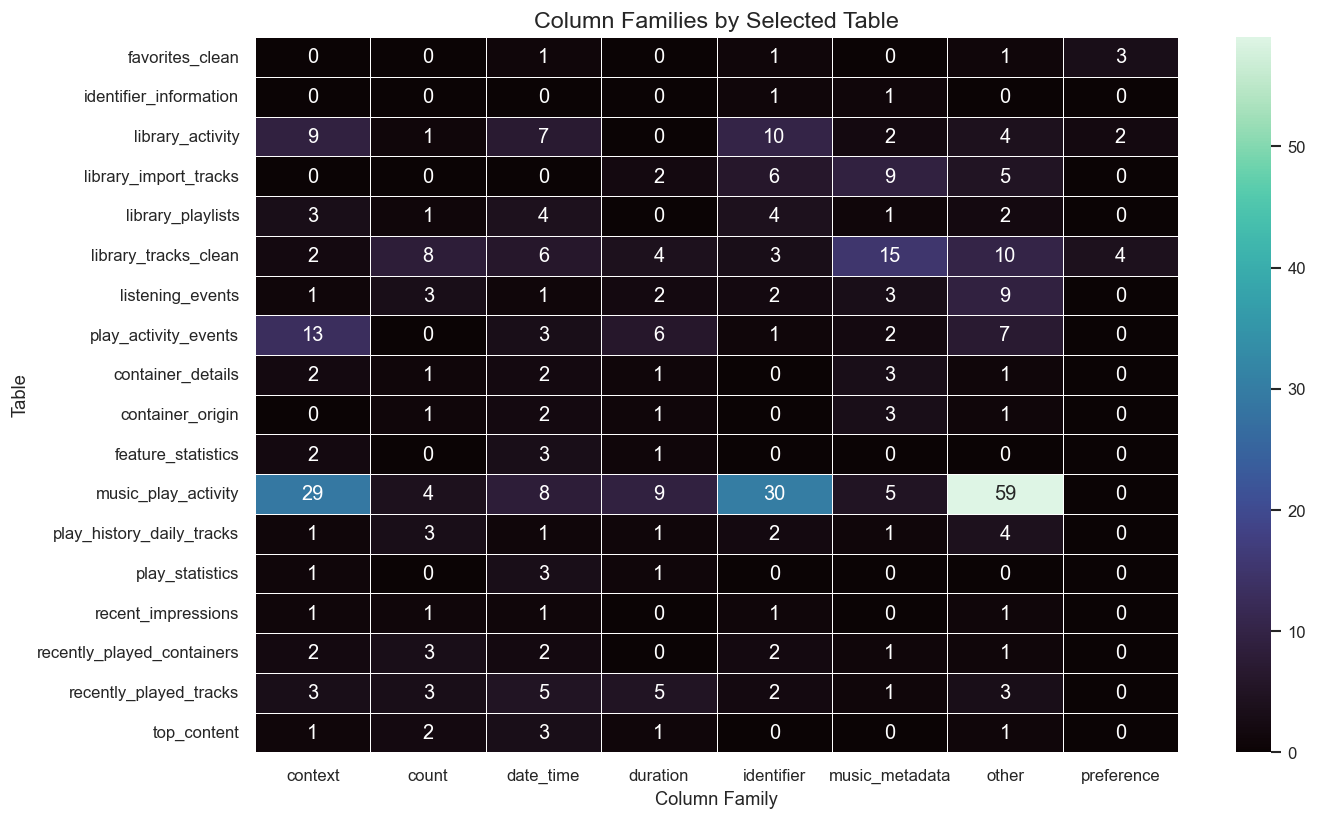

Saved Figure: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/data_check/column_families_by_selected_table.png


In [115]:
plot_data = families.copy()

plot_data = plot_data.merge(
    contracts[["preferred_key", "canonical_name"]],
    left_on="table_key",
    right_on="preferred_key",
    how="left",
)

plot_data = plot_data.drop(columns=["table_key", "preferred_key"])
plot_data = plot_data.set_index("canonical_name").fillna(0).astype(int)

plt.figure(figsize=(12, 7))

sns.heatmap(
    plot_data,
    cmap="mako",
    linewidths=0.5,
    annot=True,
    fmt="d",
)

plt.title("Column Families by Selected Table")
plt.xlabel("Column Family")
plt.ylabel("Table")
plt.tight_layout()

figure_path = save_figure("column_families_by_selected_table.png")
plt.show()

print("Saved Figure:", figure_path)

In [116]:
selected_files = (
    eda_tables
    [
        [
            "canonical_name",
            "preferred_key",
            "project_role",
            "grain",
            "next_use",
            "relative_path",
            "row_count",
            "column_count",
            "reason",
        ]
    ]
    .copy()
    .sort_values(["next_use", "row_count"], ascending=[True, False])
    .reset_index(drop=True)
)

save_table(selected_files, "selected_files_for_eda.csv")

display(selected_files)

,canonical_name,preferred_key,project_role,grain,next_use,relative_path,row_count,column_count,reason
0,play_activity_events,processed__parquet__play_activity_events,Primary Detailed Playback Event Table,One playback activity record per event,EDA Core,data/processed/parquet/play_activity_events.pa...,22872,32,This is the cleaned event-level behavioral tab...
1,library_tracks_clean,processed__parquet__library_tracks_clean,Primary Track Metadata Dimension,One library track record per resolved library ...,EDA Core,data/processed/parquet/library_tracks_clean.pa...,10738,52,This is the most analysis-ready track metadata...
2,listening_events,processed__parquet__listening_events,Primary Summary Listening Table,Track-level listening summary record,EDA Core,data/processed/parquet/listening_events.parquet,5042,21,This is the clean summary layer derived from d...
3,favorites_clean,processed__parquet__favorites_clean,Explicit Preference Table,One explicit preference record per item,EDA Core,data/processed/parquet/favorites_clean.parquet,156,6,Explicit preference is sparse but high-value f...
4,identifier_information,processed__parquet__identifier_information,Identifier Lookup Table,One identifier-to-title lookup record,EDA Support,data/processed/parquet/identifier_information....,15260,2,This table helps reconcile identifiers that do...
5,library_import_tracks,processed__parquet__library_import_tracks,Imported Track Metadata Table,One imported track record per imported source ...,EDA Support,data/processed/parquet/library_import_tracks.p...,9547,22,This table may improve identity coverage but s...
6,library_activity,processed__parquet__library_activity,Library Curation Activity Table,One library or playlist activity transaction,EDA Support,data/processed/parquet/library_activity.parquet,3842,35,This table is structurally sparse and should b...
7,recent_impressions,raw__csv__recent_impressions,Recommendation Impression Sample,One recent impression record,EDA Support,data/raw/csv/recent_impressions.csv,359,5,"This table is small and duplicated, so it shou..."
8,recently_played_tracks,raw__csv__recently_played_tracks,Recent Track Snapshot,One recent track summary record,EDA Support,data/raw/csv/recently_played_tracks.csv,200,22,"This table is a recent snapshot, not the main ..."
9,container_details,raw__csv__container_details,Container Context Table,One container detail record,EDA Support,data/raw/csv/container_details.csv,162,10,This may enrich playlist and source analysis b...


In [117]:
summary = {
    "project_root": str(root),
    "discovered_files": int(len(files)),
    "loaded_tables": int(len(tables)),
    "failed_tables": int((inventory["load_status"] == "Failed").sum()),
    "total_loaded_rows": int(loaded["row_count"].sum()),
    "total_loaded_columns": int(loaded["column_count"].sum()),
    "selected_tables": int(len(chosen_keys)),
    "eda_input_tables": int(len(eda_keys)),
    "eda_core_tables": contracts.query("next_use == 'EDA Core'")["canonical_name"].tolist(),
    "eda_support_tables": contracts.query("next_use == 'EDA Support'")["canonical_name"].tolist(),
    "validation_tables": contracts.query("next_use == 'Validation Only'")["canonical_name"].tolist(),
    "fallback_tables": contracts.query("next_use == 'Raw Fallback Only'")["canonical_name"].tolist(),
    "output_tables": str(tables_root),
    "output_figures": str(figures_root),
}

summary_path = tables_root / "data_check_summary.json"

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=4, default=str)

print("Data Check Summary:", summary_path)
print(json.dumps(summary, indent=4))

Data Check Summary: /Users/Sumaitat/Documents/Coding/music-analytics/reports/tables/data_check/data_check_summary.json
{
    "project_root": "/Users/Sumaitat/Documents/Coding/music-analytics",
    "discovered_files": 56,
    "loaded_tables": 56,
    "failed_tables": 0,
    "total_loaded_rows": 266428,
    "total_loaded_columns": 1022,
    "selected_tables": 18,
    "eda_input_tables": 16,
    "eda_core_tables": [
        "play_activity_events",
        "listening_events",
        "library_tracks_clean",
        "favorites_clean"
    ],
    "eda_support_tables": [
        "identifier_information",
        "library_import_tracks",
        "library_playlists",
        "library_activity",
        "recent_impressions",
        "recently_played_tracks",
        "recently_played_containers",
        "container_details",
        "container_origin"
    ],
    "validation_tables": [
        "top_content",
        "play_statistics",
        "feature_statistics"
    ],
    "fallback_tables": [
   

In [119]:
print("Tables Directory:", tables_root)
print("Figures Directory:", figures_root)
print("EDA Input Table File:", tables_root / "eda_input_tables.csv")
print("Selected Files for EDA File:", tables_root / "selected_files_for_eda.csv")
print("Join Quality Report:", tables_root / "join_quality_report.csv")
print("Table Contracts:", tables_root / "table_contracts.csv")

Tables Directory: /Users/Sumaitat/Documents/Coding/music-analytics/reports/tables/data_check
Figures Directory: /Users/Sumaitat/Documents/Coding/music-analytics/reports/figures/data_check
EDA Input Table File: /Users/Sumaitat/Documents/Coding/music-analytics/reports/tables/data_check/eda_input_tables.csv
Selected Files for EDA File: /Users/Sumaitat/Documents/Coding/music-analytics/reports/tables/data_check/selected_files_for_eda.csv
Join Quality Report: /Users/Sumaitat/Documents/Coding/music-analytics/reports/tables/data_check/join_quality_report.csv
Table Contracts: /Users/Sumaitat/Documents/Coding/music-analytics/reports/tables/data_check/table_contracts.csv
